# ♻️ 12-Class Garbage Classification with PyTorch & Transfer Learning
### Optimized for Google Colab Tesla T4 GPU (15GB VRAM)

**Dataset**: [Kaggle Garbage Classification (12 classes)](https://www.kaggle.com/datasets/mostafaabla/garbage-classification) by Mostafa Abla  
**Classes (12)**: `battery`, `biological`, `brown-glass`, `cardboard`, `clothes`, `green-glass`, `metal`, `paper`, `plastic`, `shoes`, `trash`, `white-glass`  
**Architecture**: Transfer Learning with Pre-trained `EfficientNet-B0` (with ResNet-50 alternative provided)

---

### Key Highlights of this Notebook:
- **Zero-Fuss Kaggle Download**: Automated `.env` / API token authentication and KaggleHub extraction.
- **Tesla T4 Optimization**: Uses PyTorch Automatic Mixed Precision (`torch.amp.autocast`), `pin_memory=True`, and `num_workers=2` for fast training.
- **Data Augmentation**: Robust data augmentations for training while keeping validation evaluation clean and uncorrupted.
- **Stratified Split**: 80/20 train/validation split preserving exact class ratios across all 12 classes.
- **Comprehensive Visualizations**:
  1. Loss & Accuracy learning curves across epochs.
  2. Confusion Matrix heatmap (via Seaborn) highlighting true vs. predicted performance.
  3. Scikit-learn Classification Report (Precision, Recall, F1-Score).
  4. 3x3 Visual Inference Prediction Grid with confidence scores and color highlighting.
  5. Interactive Top-K single image inference tester.


## 1. Environment & Device Setup
We start by verifying CUDA GPU availability, checking device memory specifications (Tesla T4 has 15GB VRAM), and setting random seeds for reproducibility.


In [2]:
# ==============================================================================
# 1. Environment & Device Setup
# ==============================================================================
import os
import sys
import time
import copy
import random
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm

# Set seed for reproducible results across runs
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Check and configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Using device: {device}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    total_mem_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    cuda_ver = torch.version.cuda
    cudnn_ver = torch.backends.cudnn.version()
    print(f"--> GPU Device Name : {gpu_name}")
    print(f"--> Total GPU Memory: {total_mem_gb:.2f} GB VRAM")
    print(f"--> CUDA Version    : {cuda_ver} | cuDNN Version: {cudnn_ver}")
    print("--> GPU acceleration active! Ready for mixed-precision training.")
else:
    print("--> [WARNING] GPU not detected. Running on CPU.")
    print("    If using Google Colab, go to 'Runtime' -> 'Change runtime type' -> Select 'T4 GPU'.")


--> Using device: cuda
--> GPU Device Name : Tesla T4
--> Total GPU Memory: 14.56 GB VRAM
--> CUDA Version    : 13.0 | cuDNN Version: 92800
--> GPU acceleration active! Ready for mixed-precision training.


## 2. Automated Kaggle Authentication & Dataset Download

To download the dataset automatically using your Kaggle API credentials:
1. **Automated Credential Discovery**: Reads your `api_key` or `KAGGLE_API_TOKEN` directly from the local `.env` file or environment variables without requiring manual file uploads or browser prompts.
2. **KaggleHub & CLI Compatibility**: Configures both modern Kaggle Access Tokens (`KGAT_...` in `~/.kaggle/access_token`) and legacy keys (`~/.kaggle/kaggle.json`).
3. **Automated Download & Extraction**: Downloads `mostafaabla/garbage-classification` (~15,500 images across 12 classes) using `kagglehub` with automatic fallback to `kaggle` CLI.


In [5]:
# ==============================================================================
# 2. Automated Download on Remote Colab GPU
# ==============================================================================
import os
from pathlib import Path

# Set your Kaggle API Token from .env
KAGGLE_TOKEN = "KGAT_48eb9e656f356f64cf59d1a3d72972f1"

os.environ["KAGGLE_API_TOKEN"] = KAGGLE_TOKEN
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)
(kaggle_dir / "access_token").write_text(KAGGLE_TOKEN.strip())

# Check / install kagglehub
try:
    import kagglehub
except ImportError:
    !pip install -q kagglehub
    import kagglehub

print("--> Downloading dataset directly to remote Tesla T4 GPU...")
downloaded_path = kagglehub.dataset_download("mostafaabla/garbage-classification")
download_dir = Path(downloaded_path)

print(f"--> [SUCCESS] Dataset ready on remote GPU at: {download_dir}")

--> Downloading dataset directly to remote Tesla T4 GPU...
Using Colab cache for faster access to the 'garbage-classification' dataset.
--> [SUCCESS] Dataset ready on remote GPU at: /kaggle/input/garbage-classification


### 2.1 Dataset Location Verification
Confirms the target directory where the dataset is stored and accessible for DataLoader ingestion.


In [6]:
# Verify download directory
print(f"--> Dataset Directory Path: {download_dir.resolve()}")
print(f"--> Exists on filesystem : {download_dir.exists()}")


--> Dataset Directory Path: /kaggle/input/garbage-classification
--> Exists on filesystem : True


### 2.2 Discover Dataset Root & Inspect Class Distribution
Depending on how the zip is unpacked, the images may be directly in `download_dir` or inside a nested subfolder like `garbage_classification/garbage_classification`.  
The helper below locates the exact directory containing the 12 class folders and reports image counts.


In [7]:
# ==============================================================================
# 2.2 Dataset Root Discovery & Class Breakdown
# ==============================================================================
def find_dataset_root(search_dir: Path):
    target_classes = {"battery", "biological", "cardboard", "plastic", "paper", "metal"}
    
    # Check root, depth 1, and depth 2
    candidates = [search_dir] + [p for p in search_dir.glob("*") if p.is_dir()]
    candidates += [p for p in search_dir.glob("*/*") if p.is_dir()]
    
    for candidate in candidates:
        subdirs = {d.name.lower().replace("_", "-") for d in candidate.iterdir() if d.is_dir()}
        if len(target_classes.intersection(subdirs)) >= 4:
            return candidate
            
    return search_dir

data_root = find_dataset_root(download_dir)
print(f"--> Discovered Dataset Root: {data_root.resolve()}")

# List all class directories
classes = sorted([d.name for d in data_root.iterdir() if d.is_dir()])
print(f"--> Found {len(classes)} classes: {classes}")

# Count images per class
class_counts = {}
for cls_name in classes:
    cls_path = data_root / cls_name
    count = len(list(cls_path.glob("*.jpg")) + list(cls_path.glob("*.png")) + list(cls_path.glob("*.jpeg")))
    class_counts[cls_name] = count

print("\n" + "="*50)
print(f"{'Class Name':<20} {'Sample Count':>12}")
print("="*50)
for cls_name, count in class_counts.items():
    print(f"{cls_name:<20} {count:>12d}")
print("="*50)
print(f"{'Total Images':<20} {sum(class_counts.values()):>12d}")
print("="*50)


--> Discovered Dataset Root: /kaggle/input/garbage-classification/garbage_classification
--> Found 12 classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']

Class Name           Sample Count
battery                       945
biological                    985
brown-glass                   607
cardboard                     891
clothes                      5325
green-glass                   629
metal                         769
paper                        1050
plastic                       865
shoes                        1977
trash                         697
white-glass                   775
Total Images                15515


## 3. Data Transforms, Stratified Splitting & DataLoaders

### Data Augmentation Strategy:
- **Training Set Transforms**:
  - `Resize((224, 224))` - Standard input resolution for EfficientNet and ResNet.
  - `RandomHorizontalFlip(p=0.5)` - Flips images horizontally to teach rotation invariance.
  - `RandomRotation(degrees=15)` - Slight rotation simulating varying orientations of garbage items.
  - `ColorJitter(brightness=0.1, contrast=0.1)` - Robustness to lighting variations.
  - `ToTensor()` & `Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])` - Pre-trained ImageNet stats.
- **Validation Set Transforms**:
  - `Resize((224, 224))`
  - `ToTensor()` & `Normalize(...)` (no random augmentations for consistent, unbiased evaluation).

### Stratified 80/20 Train/Validation Split:
We use `sklearn.model_selection.train_test_split(..., stratify=targets)` to ensure each of the 12 classes maintains the exact same proportion in both training (80%) and validation (20%) sets.

### DataLoader Configuration for Tesla T4 GPU:
- `batch_size = 32` - Optimal batch size for T4 memory throughput and gradient stability.
- `num_workers = 2` - Maximizes data loading performance on Google Colab's 2 vCPU environment.
- `pin_memory = True` - Pins host memory for fast DMA transfers into GPU VRAM.


In [8]:
# ==============================================================================
# 3. Transforms, Custom Subset Wrapper, and DataLoaders
# ==============================================================================

# Standard ImageNet normalization values
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Transforms for training (with data augmentation)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Transforms for validation (pure evaluation without augmentations)
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Custom Dataset Wrapper to apply different transforms to subsets
class TransformedSubset(Dataset):
    """
    Applies custom transforms dynamically to a subset of an ImageFolder dataset.
    This guarantees that the validation split never undergoes training augmentations.
    """
    def __init__(self, base_dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        image, label = self.base_dataset[real_idx]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

    def __len__(self):
        return len(self.indices)

# Load base dataset without transform
raw_dataset = datasets.ImageFolder(root=str(data_root), transform=None)
class_names = raw_dataset.classes
num_classes = len(class_names)
print(f"--> Base dataset loaded: {len(raw_dataset)} images across {num_classes} classes.")

# Perform Stratified 80/20 train/validation split
labels = [label for _, label in raw_dataset.samples]
train_indices, val_indices = train_test_split(
    list(range(len(raw_dataset))),
    test_size=0.20,
    stratify=labels,
    random_state=42
)

# Instantiate train and validation datasets with respective transforms
train_dataset = TransformedSubset(raw_dataset, train_indices, transform=train_transforms)
val_dataset = TransformedSubset(raw_dataset, val_indices, transform=val_transforms)

print(f"--> Training subset   : {len(train_dataset)} samples ({len(train_dataset)/len(raw_dataset)*100:.1f}%)")
print(f"--> Validation subset : {len(val_dataset)} samples ({len(val_dataset)/len(raw_dataset)*100:.1f}%)")

# DataLoader Configuration optimized for Tesla T4 GPU
BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print(f"--> DataLoaders ready: {len(train_loader)} train batches | {len(val_loader)} validation batches per epoch.")


--> Base dataset loaded: 15515 images across 12 classes.
--> Training subset   : 12412 samples (80.0%)
--> Validation subset : 3103 samples (20.0%)
--> DataLoaders ready: 388 train batches | 97 validation batches per epoch.


### 3.1 Verify Batch Dimensions & Inspect Augmented Training Images
Let's verify tensor dimensions and display a grid of augmented training images after denormalization.


--> Batch Images Shape: torch.Size([32, 3, 224, 224]) -> (Batch Size, Channels, Height, Width)
--> Batch Labels Shape: torch.Size([32])


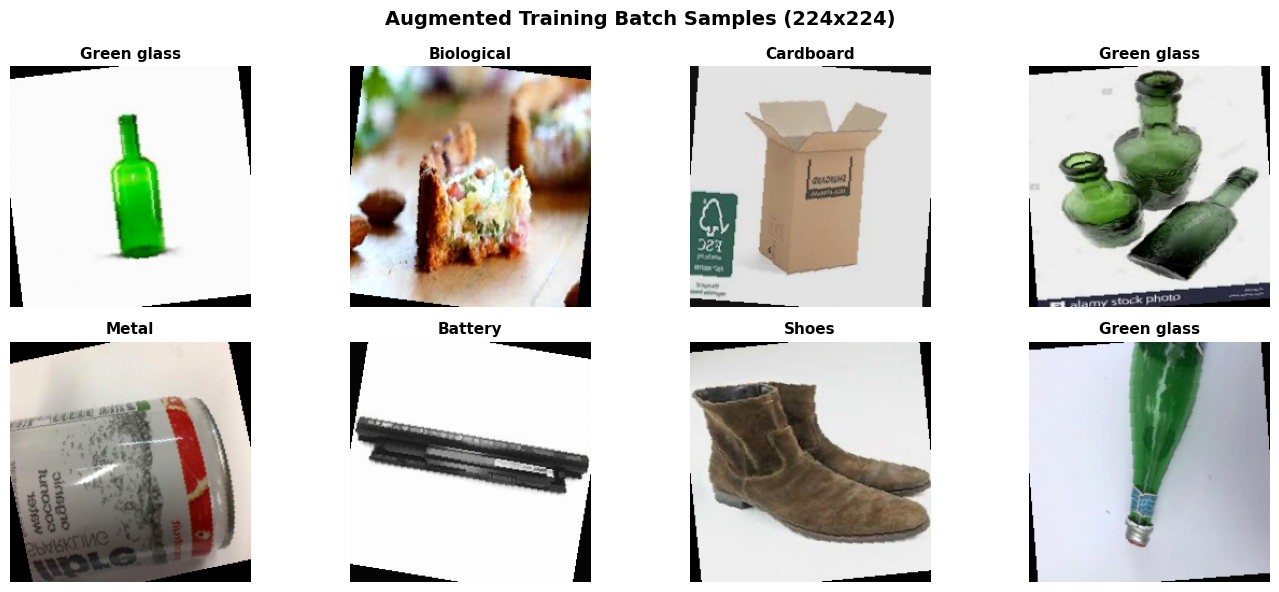

In [9]:
# Helper function to revert ImageNet normalization for plotting
def denormalize_image(tensor):
    img = tensor.clone().detach().cpu()
    for channel, mean, std in zip(img, IMAGENET_MEAN, IMAGENET_STD):
        channel.mul_(std).add_(mean)
    img = torch.clamp(img, 0, 1)
    return img.permute(1, 2, 0).numpy()

# Inspect one batch from the training loader
sample_imgs, sample_lbls = next(iter(train_loader))
print(f"--> Batch Images Shape: {sample_imgs.shape} -> (Batch Size, Channels, Height, Width)")
print(f"--> Batch Labels Shape: {sample_lbls.shape}")

# Plot 8 augmented sample images from the batch
plt.figure(figsize=(14, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(denormalize_image(sample_imgs[i]))
    cls_title = class_names[sample_lbls[i].item()].replace("-", " ").capitalize()
    plt.title(cls_title, fontsize=11, fontweight='bold')
    plt.axis("off")
plt.suptitle("Augmented Training Batch Samples (224x224)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Model Architecture: Transfer Learning with EfficientNet-B0
We use **EfficientNet-B0** pre-trained on ImageNet:
1. It achieves high Top-1 accuracy with only ~4-5 million parameters.
2. It processes batches rapidly on a Tesla T4 GPU while using minimal VRAM.
3. We **freeze** all backbone feature extractor layers (`param.requires_grad = False`).
4. We replace the classifier head:
   ```python
   model.classifier = nn.Sequential(
       nn.Dropout(p=0.3, inplace=True),
       nn.Linear(in_features=1280, out_features=12)
   )
   ```
*(An alternative ResNet-50 architecture is also implemented in the helper below if needed).*


In [10]:
# ==============================================================================
# 4. Model Definition & Classifier Head Adaptation
# ==============================================================================

def create_garbage_classifier(num_classes=12, model_name="efficientnet_b0"):
    """
    Builds a transfer learning model with frozen backbone and custom classifier head.
    """
    if model_name == "efficientnet_b0":
        # Load pre-trained EfficientNet-B0 weights
        weights = models.EfficientNet_B0_Weights.DEFAULT
        model = models.efficientnet_b0(weights=weights)
        
        # Freeze backbone feature extraction layers
        for param in model.features.parameters():
            param.requires_grad = False
            
        # Replace final classifier head
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.3, inplace=True),
            nn.Linear(in_features, num_classes)
        )
        print(f"--> Loaded EfficientNet-B0: Feature extractor frozen, new classifier head (1280 -> {num_classes})")
        
    elif model_name == "resnet50":
        # ResNet-50 alternative
        weights = models.ResNet50_Weights.DEFAULT
        model = models.resnet50(weights=weights)
        
        # Freeze backbone
        for param in model.parameters():
            param.requires_grad = False
            
        # Replace final fully connected layer
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, num_classes)
        )
        print(f"--> Loaded ResNet-50: Feature extractor frozen, new fc head ({in_features} -> {num_classes})")
    else:
        raise ValueError(f"Unsupported model: {model_name}")

    return model

# Instantiate and move to device
model = create_garbage_classifier(num_classes=num_classes, model_name="efficientnet_b0")
model = model.to(device)

# Audit parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print(f"--> Total Parameters     : {total_params:,}")
print(f"--> Trainable Parameters : {trainable_params:,} ({trainable_params/total_params*100:.2f}%)")
print(f"--> Frozen Parameters    : {frozen_params:,} ({frozen_params/total_params*100:.2f}%)")


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 154MB/s]


--> Loaded EfficientNet-B0: Feature extractor frozen, new classifier head (1280 -> 12)
--> Total Parameters     : 4,022,920
--> Trainable Parameters : 15,372 (0.38%)
--> Frozen Parameters    : 4,007,548 (99.62%)


## 5. Loss Function, Optimizer & Automatic Mixed Precision (AMP)
- **Criterion**: `nn.CrossEntropyLoss()` for multi-class classification.
- **Optimizer**: `optim.Adam` targeting only the trainable parameters of the classifier head with learning rate $0.001$ (`1e-3`) and $L_2$ weight decay $1e-4$.
- **Learning Rate Scheduler**: `ReduceLROnPlateau` decreases LR by 50% when validation loss ceases to improve for 2 epochs.
- **Mixed Precision**: `torch.amp.GradScaler('cuda')` runs forward passes in `float16` on T4 Tensor Cores, cutting memory usage in half and speeding up training.


In [11]:
# ==============================================================================
# 5. Loss, Optimizer, Scheduler & Mixed Precision Scaler
# ==============================================================================

# Cross Entropy Loss
criterion = nn.CrossEntropyLoss()

# Adam optimizer configured on trainable parameters only
trainable_parameters = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.Adam(trainable_parameters, lr=0.001, weight_decay=1e-4)

# Dynamic learning rate reduction on plateau
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2
)

# PyTorch Automatic Mixed Precision (AMP) GradScaler
use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

print("--> Criterion : nn.CrossEntropyLoss")
print(f"--> Optimizer : Adam (lr=0.001, weight_decay=1e-4)")
print(f"--> Scheduler : ReduceLROnPlateau (factor=0.5, patience=2)")
print(f"--> AMP Scaler: {'Enabled (CUDA float16)' if use_amp else 'Disabled (CPU)'}")


--> Criterion : nn.CrossEntropyLoss
--> Optimizer : Adam (lr=0.001, weight_decay=1e-4)
--> Scheduler : ReduceLROnPlateau (factor=0.5, patience=2)
--> AMP Scaler: Enabled (CUDA float16)


## 6. Training & Validation Loop (5 to 10 Epochs)
We train for **8 epochs** (configurable between 5 and 10), which takes only ~4-6 minutes on a Colab Tesla T4 GPU.
Features of this loop:
- Tracks and records `train_loss`, `train_acc`, `val_loss`, and `val_acc` per epoch.
- Updates the `tqdm` progress bar with current batch loss.
- Saves the best checkpoint based on validation accuracy to `best_garbage_classifier.pth`.


In [12]:
# ==============================================================================
# 6. Training and Validation Loop
# ==============================================================================

NUM_EPOCHS = 10  # 5 to 10 epochs is optimal for fast training on Tesla T4
CHECKPOINT_PATH = "best_garbage_classifier.pth"

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0
total_training_start = time.time()

print(f"--> Starting training for {NUM_EPOCHS} epochs on {device}...")
print("=" * 80)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start_time = time.time()
    
    # ------------------------------------
    # A. TRAINING PHASE
    # ------------------------------------
    model.train()
    running_train_loss = 0.0
    running_train_correct = 0
    total_train_samples = 0
    
    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} [Train]", leave=False)
    for images, labels in train_pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        batch_sz = images.size(0)
        
        optimizer.zero_grad(set_to_none=True)
        
        # Forward pass with Automatic Mixed Precision
        with torch.amp.autocast('cuda', enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)
            
        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        # Metrics accumulation
        running_train_loss += loss.item() * batch_sz
        _, preds = torch.max(outputs, 1)
        running_train_correct += torch.sum(preds == labels.data).item()
        total_train_samples += batch_sz
        
        train_pbar.set_postfix({"loss": f"{loss.item():.4f}"})
        
    epoch_train_loss = running_train_loss / total_train_samples
    epoch_train_acc = running_train_correct / total_train_samples
    
    # ------------------------------------
    # B. VALIDATION PHASE
    # ------------------------------------
    model.eval()
    running_val_loss = 0.0
    running_val_correct = 0
    total_val_samples = 0
    
    val_pbar = tqdm(val_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} [Valid]", leave=False)
    with torch.no_grad():
        for images, labels in val_pbar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            batch_sz = images.size(0)
            
            with torch.amp.autocast('cuda', enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
                
            running_val_loss += loss.item() * batch_sz
            _, preds = torch.max(outputs, 1)
            running_val_correct += torch.sum(preds == labels.data).item()
            total_val_samples += batch_sz
            
            val_pbar.set_postfix({"val_loss": f"{loss.item():.4f}"})
            
    epoch_val_loss = running_val_loss / total_val_samples
    epoch_val_acc = running_val_correct / total_val_samples
    
    # Adjust learning rate based on validation loss
    scheduler.step(epoch_val_loss)
    current_lr = optimizer.param_groups[0]['lr']
    
    # Record history
    history["train_loss"].append(epoch_train_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_loss"].append(epoch_val_loss)
    history["val_acc"].append(epoch_val_acc)
    
    epoch_elapsed = time.time() - epoch_start_time
    
    # Checkpoint saving for best model
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_acc': best_val_acc,
            'class_names': class_names
        }, CHECKPOINT_PATH)
        best_tag = "🌟 (New Best!)"
    else:
        best_tag = ""
        
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} [{epoch_elapsed:.1f}s] | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:6.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc*100:6.2f}% | "
          f"LR: {current_lr:.6f} {best_tag}")

total_elapsed = time.time() - total_training_start
print("=" * 80)
print(f"--> Training completed in {total_elapsed//60:.0f}m {total_elapsed%60:.0f}s")
print(f"--> Best Validation Accuracy: {best_val_acc*100:.2f}% (Saved to '{CHECKPOINT_PATH}')")


--> Starting training for 10 epochs on cuda...


Epoch 01/10 [Train]:   0%|          | 0/388 [00:00<?, ?it/s]

Epoch 01/10 [Valid]:   0%|          | 0/97 [00:00<?, ?it/s]

Epoch 01/10 [116.6s] | Train Loss: 0.7464 | Train Acc:  80.33% | Val Loss: 0.3896 | Val Acc:  90.53% | LR: 0.001000 🌟 (New Best!)


Epoch 02/10 [Train]:   0%|          | 0/388 [00:00<?, ?it/s]

Epoch 02/10 [Valid]:   0%|          | 0/97 [00:00<?, ?it/s]

... (25 outputs left out)

Epoch 09/10 [80.9s] | Train Loss: 0.2873 | Train Acc:  90.87% | Val Loss: 0.2390 | Val Acc:  92.94% | LR: 0.001000 


Epoch 10/10 [Train]:   0%|          | 0/388 [00:00<?, ?it/s]

Epoch 10/10 [Valid]:   0%|          | 0/97 [00:00<?, ?it/s]

Epoch 10/10 [80.8s] | Train Loss: 0.2712 | Train Acc:  91.36% | Val Loss: 0.2352 | Val Acc:  93.17% | LR: 0.001000 
--> Training completed in 14m 11s
--> Best Validation Accuracy: 93.30% (Saved to 'best_garbage_classifier.pth')


## 7. Evaluation & Visualization

We now evaluate the model thoroughly on the held-out validation set:
1. **Reload Best Weights**: Load `best_garbage_classifier.pth` to ensure all evaluations use the peak performing model.
2. **Chart 1**: Training vs. Validation Loss and Accuracy curves across all epochs.
3. **Chart 2**: Seaborn Confusion Matrix Heatmap across all 12 garbage categories.
4. **Classification Report**: Precision, Recall, and F1-score per class via Scikit-Learn.
5. **Sample Grid**: 3x3 grid of validation test images comparing True vs. Predicted labels with color highlighting (green for correct, red for incorrect) and prediction confidence percentages.


In [13]:
# ==============================================================================
# 7.1 Load Best Checkpoint & Run Full Validation Inference
# ==============================================================================

# Load best checkpoint
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"--> Loaded best model checkpoint from Epoch {checkpoint['epoch']} with Val Accuracy: {checkpoint['best_val_acc']*100:.2f}%")

# Collect predictions, ground-truth targets, and predicted probabilities
all_targets = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Running Validation Set Inference"):
        images = images.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=use_amp):
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(probs, dim=1)
            
        all_targets.extend(labels.cpu().numpy())
        all_predictions.extend(preds.cpu().numpy())
        all_probabilities.extend(probs.cpu().numpy())

all_targets = np.array(all_targets)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

final_val_acc = (all_targets == all_predictions).mean()
print(f"--> Final Validation Set Accuracy: {final_val_acc * 100:.2f}%")


--> Loaded best model checkpoint from Epoch 4 with Val Accuracy: 93.30%


Running Validation Set Inference:   0%|          | 0/97 [00:00<?, ?it/s]

--> Final Validation Set Accuracy: 93.30%


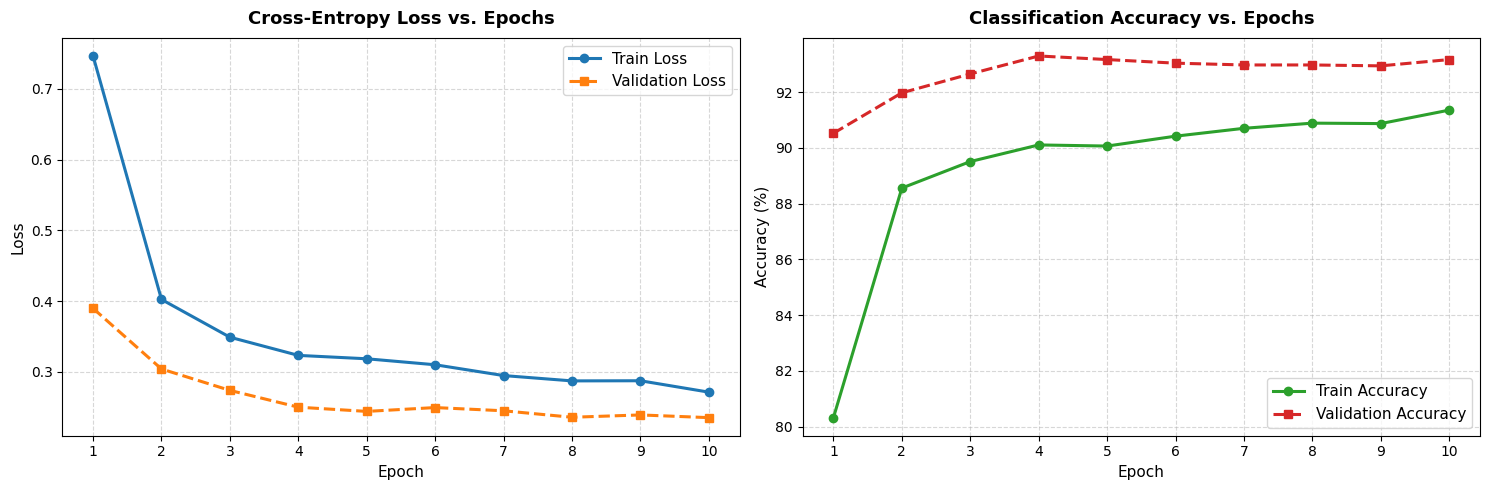

In [15]:
# ==============================================================================
# 7.2 Chart 1: Training vs. Validation Loss and Accuracy Curves
# ==============================================================================

epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(15, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], 'o-', color='#1f77b4', linewidth=2.2, label="Train Loss")
plt.plot(epochs_range, history["val_loss"], 's--', color='#ff7f0e', linewidth=2.2, label="Validation Loss")
plt.title("Cross-Entropy Loss vs. Epochs", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Loss", fontsize=11)
plt.xticks(epochs_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, [acc * 100 for acc in history["train_acc"]], 'o-', color='#2ca02c', linewidth=2.2, label="Train Accuracy")
plt.plot(epochs_range, [acc * 100 for acc in history["val_acc"]], 's--', color='#d62728', linewidth=2.2, label="Validation Accuracy")
plt.title("Classification Accuracy vs. Epochs", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Accuracy (%)", fontsize=11)
plt.xticks(epochs_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()


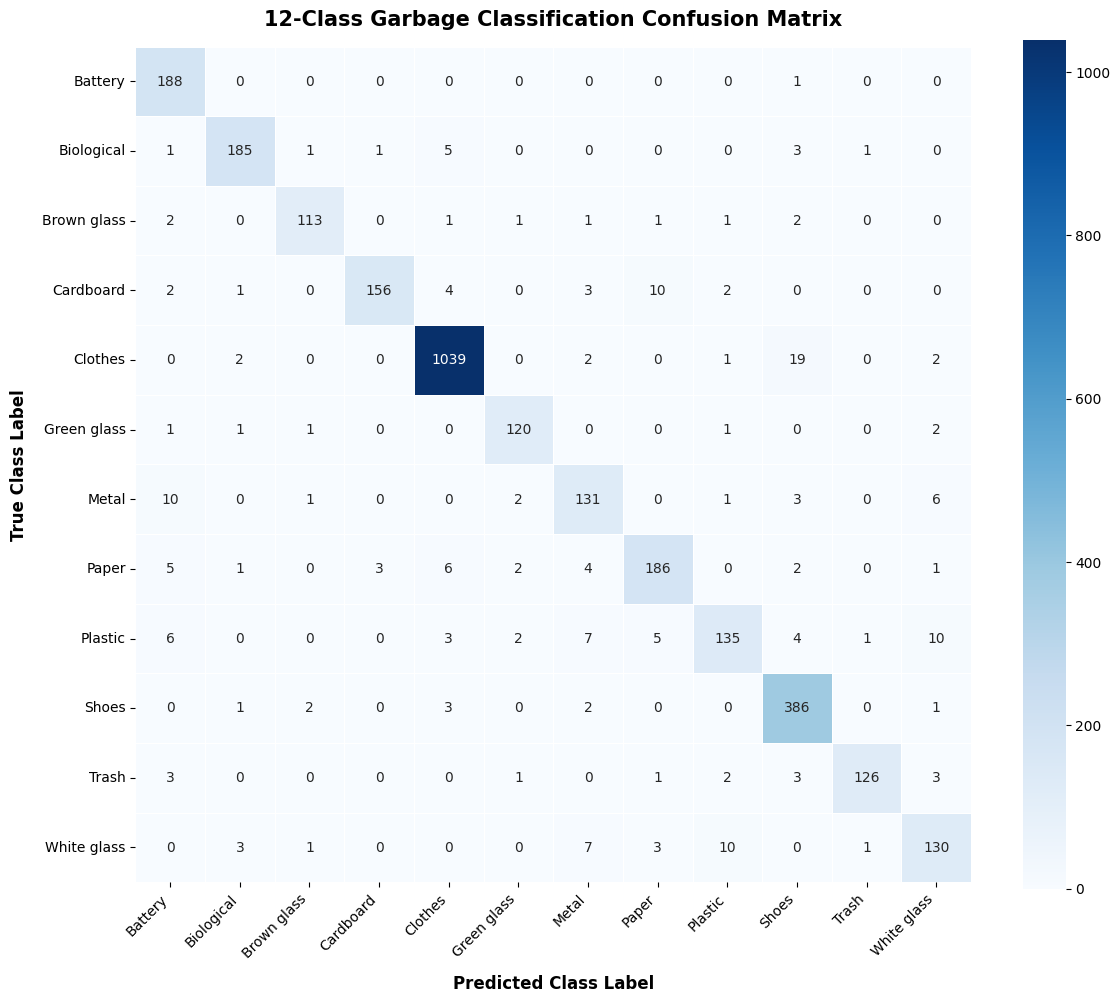

In [16]:
# ==============================================================================
# 7.3 Chart 2: Confusion Matrix Heatmap (Seaborn)
# ==============================================================================

cm = confusion_matrix(all_targets, all_predictions)
formatted_classes = [c.replace("-", " ").capitalize() for c in class_names]

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=formatted_classes,
    yticklabels=formatted_classes,
    cbar=True,
    linewidths=0.5,
    square=True
)

plt.title("12-Class Garbage Classification Confusion Matrix", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Predicted Class Label", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("True Class Label", fontsize=12, fontweight='bold', labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()


In [17]:
# ==============================================================================
# 7.4 Classification Report (Precision, Recall, F1-Score)
# ==============================================================================

print("=" * 75)
print("               12-CLASS GARBAGE CLASSIFICATION REPORT")
print("=" * 75)
report_text = classification_report(
    all_targets,
    all_predictions,
    target_names=formatted_classes,
    digits=4
)
print(report_text)
print("=" * 75)


               12-CLASS GARBAGE CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Battery     0.8624    0.9947    0.9238       189
  Biological     0.9536    0.9391    0.9463       197
 Brown glass     0.9496    0.9262    0.9378       122
   Cardboard     0.9750    0.8764    0.9231       178
     Clothes     0.9793    0.9756    0.9774      1065
 Green glass     0.9375    0.9524    0.9449       126
       Metal     0.8344    0.8506    0.8424       154
       Paper     0.9029    0.8857    0.8942       210
     Plastic     0.8824    0.7803    0.8282       173
       Shoes     0.9125    0.9772    0.9438       395
       Trash     0.9767    0.9065    0.9403       139
 White glass     0.8387    0.8387    0.8387       155

    accuracy                         0.9330      3103
   macro avg     0.9171    0.9086    0.9117      3103
weighted avg     0.9340    0.9330    0.9327      3103



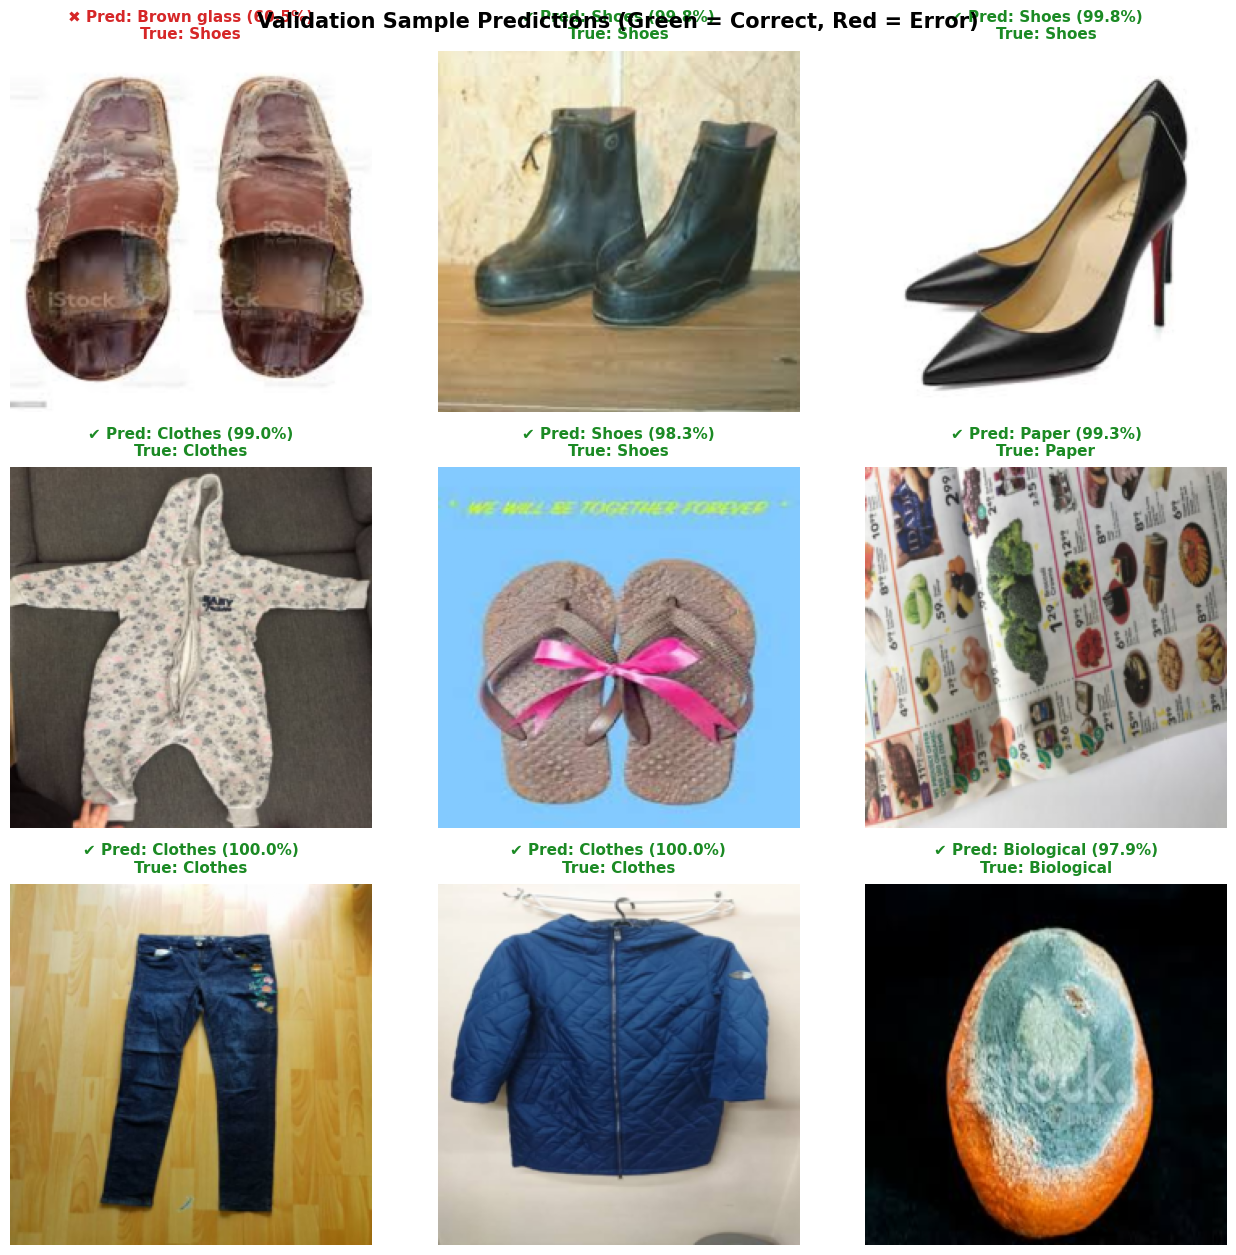

In [18]:
# ==============================================================================
# 7.5 Sample Grid: 3x3 Validation Images with True vs. Predicted
# ==============================================================================

# Seed for reproducible sample selection
np.random.seed(42)
sample_val_indices = np.random.choice(len(val_dataset), size=9, replace=False)

plt.figure(figsize=(13, 13))

for plot_idx, val_idx in enumerate(sample_val_indices):
    image_tensor, true_label_idx = val_dataset[val_idx]
    
    # Run single-image inference
    input_tensor = image_tensor.unsqueeze(0).to(device)
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=use_amp):
            output = model(input_tensor)
            probs = torch.softmax(output, dim=1).squeeze(0)
            conf, pred_label_idx = torch.max(probs, dim=0)
            
    conf_pct = conf.item() * 100
    true_name = formatted_classes[true_label_idx]
    pred_name = formatted_classes[pred_label_idx.item()]
    is_correct = (true_label_idx == pred_label_idx.item())
    
    # Styling: Green if correct, Red if mistake
    title_color = "#1b8a24" if is_correct else "#d62728"
    icon = "✔" if is_correct else "✖"
    
    img_display = denormalize_image(image_tensor)
    
    plt.subplot(3, 3, plot_idx + 1)
    plt.imshow(img_display)
    plt.axis("off")
    plt.title(
        f"{icon} Pred: {pred_name} ({conf_pct:.1f}%)\nTrue: {true_name}",
        fontsize=11,
        fontweight='bold',
        color=title_color,
        pad=8
    )

plt.suptitle("Validation Sample Predictions (Green = Correct, Red = Error)", fontsize=15, fontweight='bold', y=0.96)
plt.tight_layout()
plt.show()


## 8. Interactive Single-Image Inference Helper
You can test any image file on disk or uploaded to Colab with the helper function below. It outputs the top 3 predicted categories with confidence bars.


--> Demonstration on sample file: /kaggle/input/garbage-classification/garbage_classification/battery/battery161.jpg


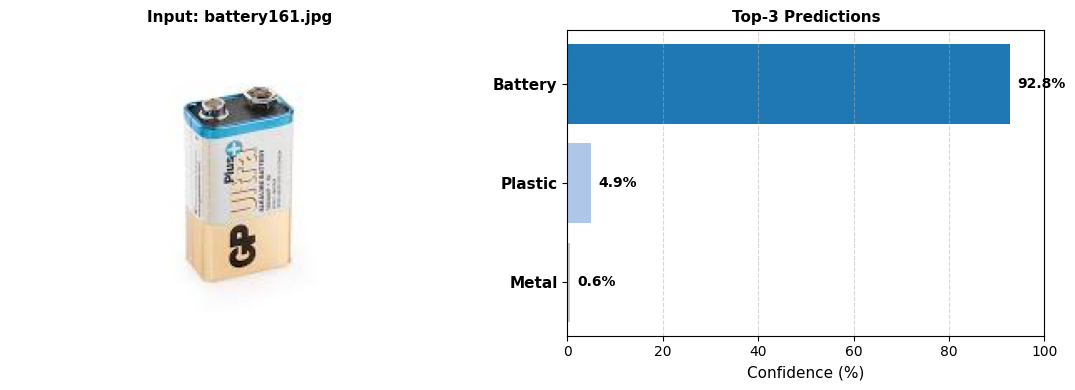

In [19]:
# ==============================================================================
# 8. Single Image Inference Function (Top-K Predictions)
# ==============================================================================

def predict_garbage_image(image_path: str, top_k: int = 3):
    """
    Performs inference on a single image file path and plots Top-K class probabilities.
    """
    if not os.path.exists(image_path):
        print(f"Error: File '{image_path}' not found.")
        return
        
    img = Image.open(image_path).convert("RGB")
    tensor_img = val_transforms(img).unsqueeze(0).to(device)
    
    model.eval()
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=use_amp):
            logits = model(tensor_img)
            probabilities = torch.softmax(logits, dim=1).squeeze(0)
            
    top_probs, top_indices = torch.topk(probabilities, k=top_k)
    top_probs = top_probs.cpu().numpy()
    top_indices = top_indices.cpu().numpy()
    
    # Plotting input image alongside Top-K horizontal bar chart
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    
    # Image Display
    ax1.imshow(img)
    ax1.axis("off")
    ax1.set_title(f"Input: {Path(image_path).name}", fontsize=11, fontweight='bold')
    
    # Probability Bar Chart
    classes_top = [formatted_classes[i] for i in top_indices]
    bar_colors = ['#1f77b4', '#aec7e8', '#c7c7c7']
    
    y_pos = np.arange(len(classes_top))
    ax2.barh(y_pos, top_probs * 100, color=bar_colors[:len(classes_top)], align='center')
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(classes_top, fontsize=11, fontweight='bold')
    ax2.invert_yaxis()
    ax2.set_xlabel("Confidence (%)", fontsize=11)
    ax2.set_xlim(0, 100)
    ax2.set_title(f"Top-{top_k} Predictions", fontsize=11, fontweight='bold')
    ax2.grid(True, axis='x', linestyle='--', alpha=0.5)
    
    for i, v in enumerate(top_probs * 100):
        ax2.text(v + 1.5, i, f"{v:.1f}%", va='center', fontweight='bold', fontsize=10)
        
    plt.tight_layout()
    plt.show()

# Test the function on the first available sample image
sample_dir = data_root / classes[0]
sample_files = list(sample_dir.glob("*.jpg")) + list(sample_dir.glob("*.png"))
if sample_files:
    print(f"--> Demonstration on sample file: {sample_files[0]}")
    predict_garbage_image(str(sample_files[0]), top_k=3)


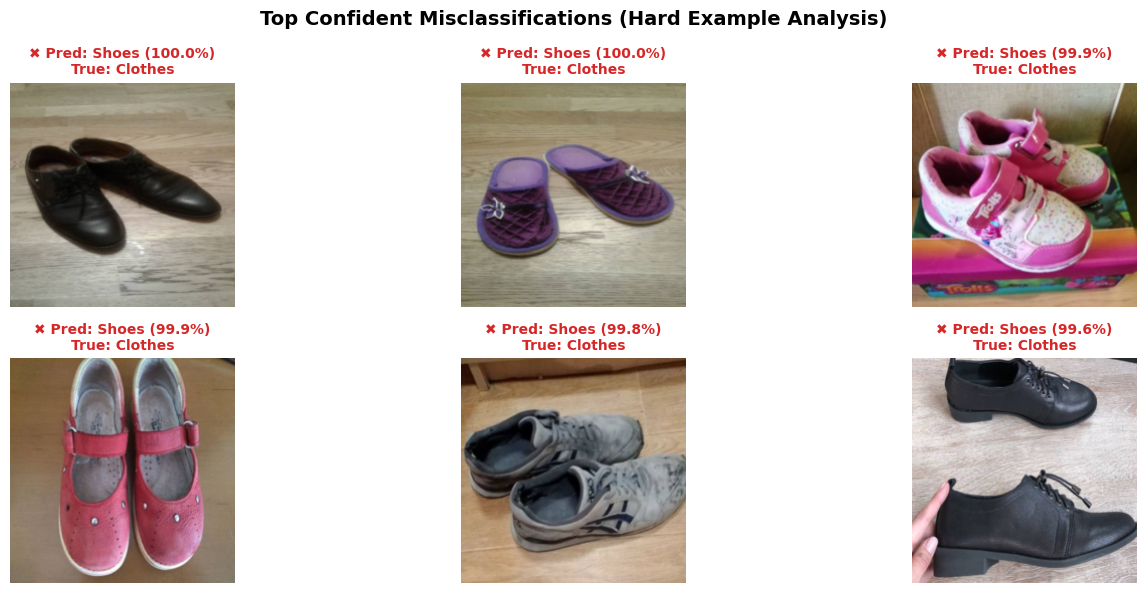

In [21]:
# ==============================================================================
# Cell B: Error Analysis (Top Confident Misclassifications)
# ==============================================================================
misclassified_indices = []
confidence_scores = []

for idx, (target, pred, probs) in enumerate(zip(all_targets, all_predictions, all_probabilities)):
    if target != pred:
        misclassified_indices.append(idx)
        confidence_scores.append(probs[pred])

# Sort errors by highest prediction confidence
sorted_error_idx = np.argsort(confidence_scores)[::-1][:6]

plt.figure(figsize=(15, 6))
for plot_num, err_pos in enumerate(sorted_error_idx):
    val_idx = misclassified_indices[err_pos]
    img_tensor, true_label = val_dataset[val_idx]
    pred_label = all_predictions[val_idx]
    conf = confidence_scores[err_pos] * 100

    plt.subplot(2, 3, plot_num + 1)
    plt.imshow(denormalize_image(img_tensor))
    plt.axis("off")
    plt.title(
        f"✖ Pred: {formatted_classes[pred_label]} ({conf:.1f}%)\nTrue: {formatted_classes[true_label]}",
        fontsize=10,
        fontweight='bold',
        color='#d62728'
    )

plt.suptitle("Top Confident Misclassifications (Hard Example Analysis)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

--> Computing 2D t-SNE projection (this takes ~10 seconds)...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


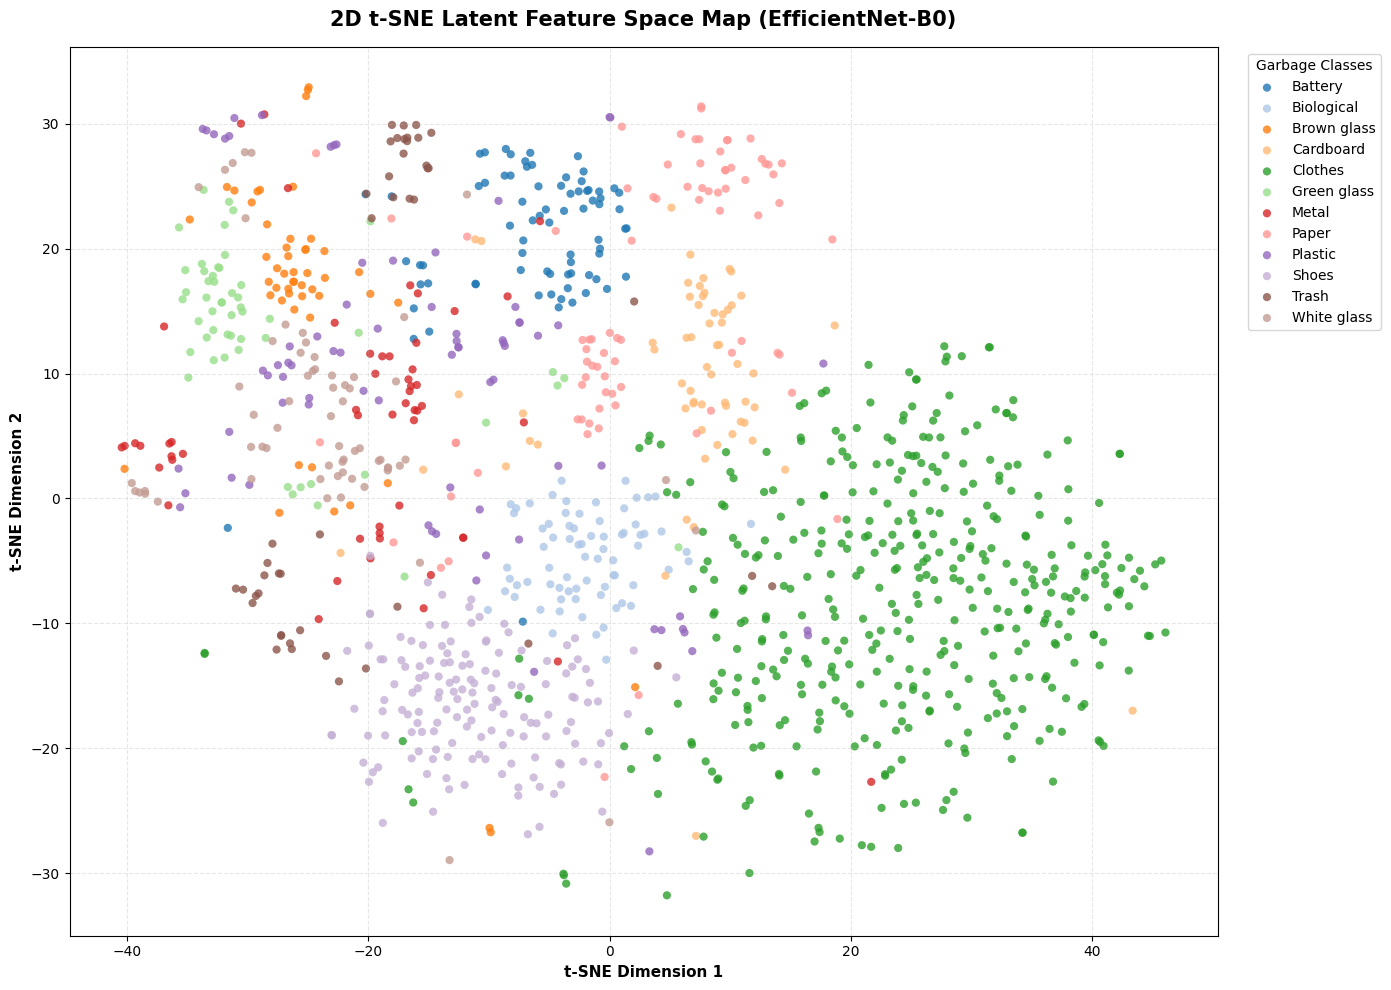

In [24]:
# ==============================================================================
# Chart 1: 2D t-SNE Feature Embedding Map
# ==============================================================================
from sklearn.manifold import TSNE

# Extract feature embeddings from EfficientNet-B0 (penultimate layer)
model.eval()
features_list = []
labels_list = []

# Sample up to 1,200 validation images for fast t-SNE computation
sample_count = 0
max_samples = 1200

with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(device)
        # Pass through backbone features and global pooling
        feats = model.features(imgs)
        pooled = nn.functional.adaptive_avg_pool2d(feats, (1, 1)).flatten(1)
        
        features_list.append(pooled.cpu().numpy())
        labels_list.append(lbls.numpy())
        sample_count += len(lbls)
        if sample_count >= max_samples:
            break

X_features = np.concatenate(features_list, axis=0)[:max_samples]
y_labels = np.concatenate(labels_list, axis=0)[:max_samples]

print("--> Computing 2D t-SNE projection (this takes ~10 seconds)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
X_tsne = tsne.fit_transform(X_features)

# Plot t-SNE scatter map
plt.figure(figsize=(14, 10))
palette = sns.color_palette("tab20", n_colors=len(formatted_classes))

for idx, cls_name in enumerate(formatted_classes):
    mask = (y_labels == idx)
    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        c=[palette[idx]],
        label=cls_name,
        alpha=0.8,
        s=35,
        edgecolors='none'
    )

plt.title("2D t-SNE Latent Feature Space Map (EfficientNet-B0)", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("t-SNE Dimension 1", fontsize=11, fontweight='bold')
plt.ylabel("t-SNE Dimension 2", fontsize=11, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Garbage Classes", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

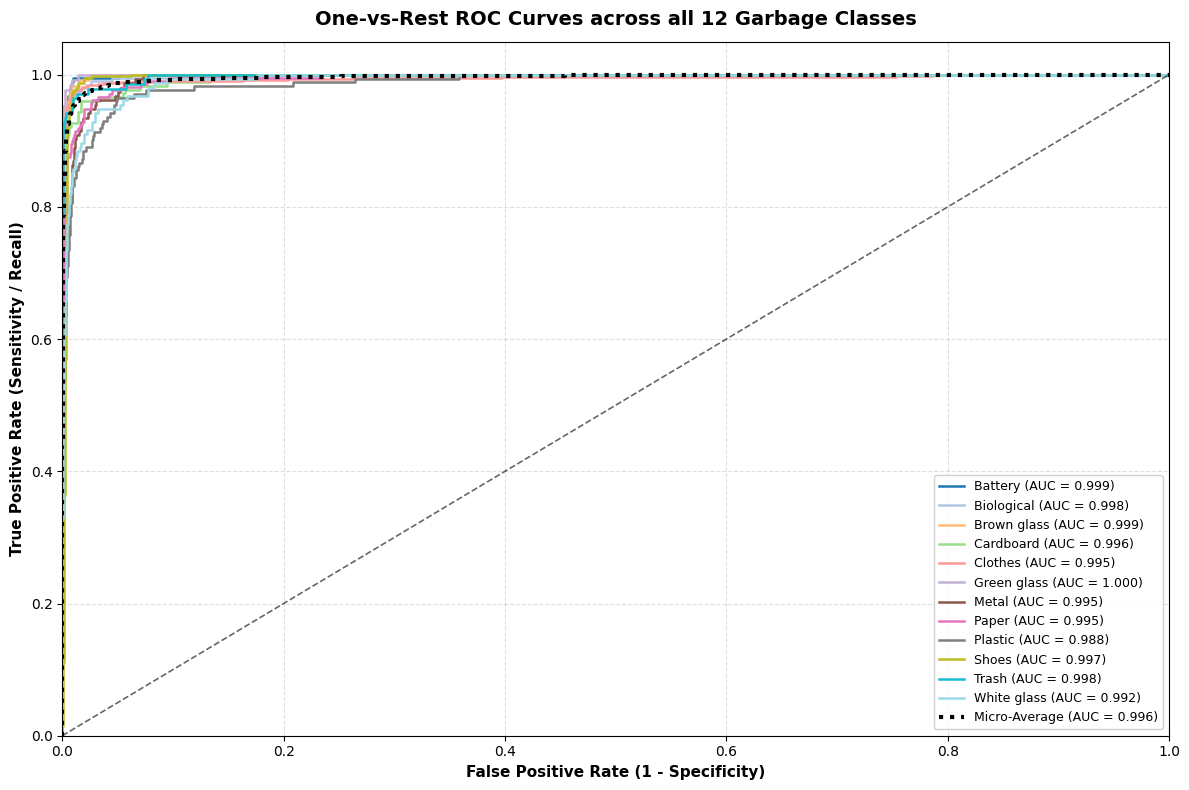

In [25]:
# ==============================================================================
# Chart 2: Multi-Class One-vs-Rest ROC Curves & AUC Analysis
# ==============================================================================
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# One-hot encode targets for 12 classes
y_onehot = label_binarize(all_targets, classes=list(range(len(formatted_classes))))

fpr = dict()
tpr = dict()
roc_auc = dict()

# Compute ROC curve and AUC per class
for i in range(len(formatted_classes)):
    fpr[i], tpr[i], _ = roc_curve(y_onehot[:, i], all_probabilities[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve
fpr["micro"], tpr["micro"], _ = roc_curve(y_onehot.ravel(), all_probabilities.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

plt.figure(figsize=(12, 8))
colors = plt.cm.tab20(np.linspace(0, 1, len(formatted_classes)))

for i, color in zip(range(len(formatted_classes)), colors):
    plt.plot(
        fpr[i], tpr[i], color=color, lw=1.8,
        label=f"{formatted_classes[i]} (AUC = {roc_auc[i]:.3f})"
    )

# Plot Micro-Average reference curve
plt.plot(
    fpr["micro"], tpr["micro"],
    label=f"Micro-Average (AUC = {roc_auc['micro']:.3f})",
    color="black", linestyle=":", lw=3
)
plt.plot([0, 1], [0, 1], "k--", lw=1.2, alpha=0.6)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight='bold')
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11, fontweight='bold')
plt.title("One-vs-Rest ROC Curves across all 12 Garbage Classes", fontsize=14, fontweight='bold', pad=12)
plt.legend(loc="lower right", fontsize=9, framealpha=0.9)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

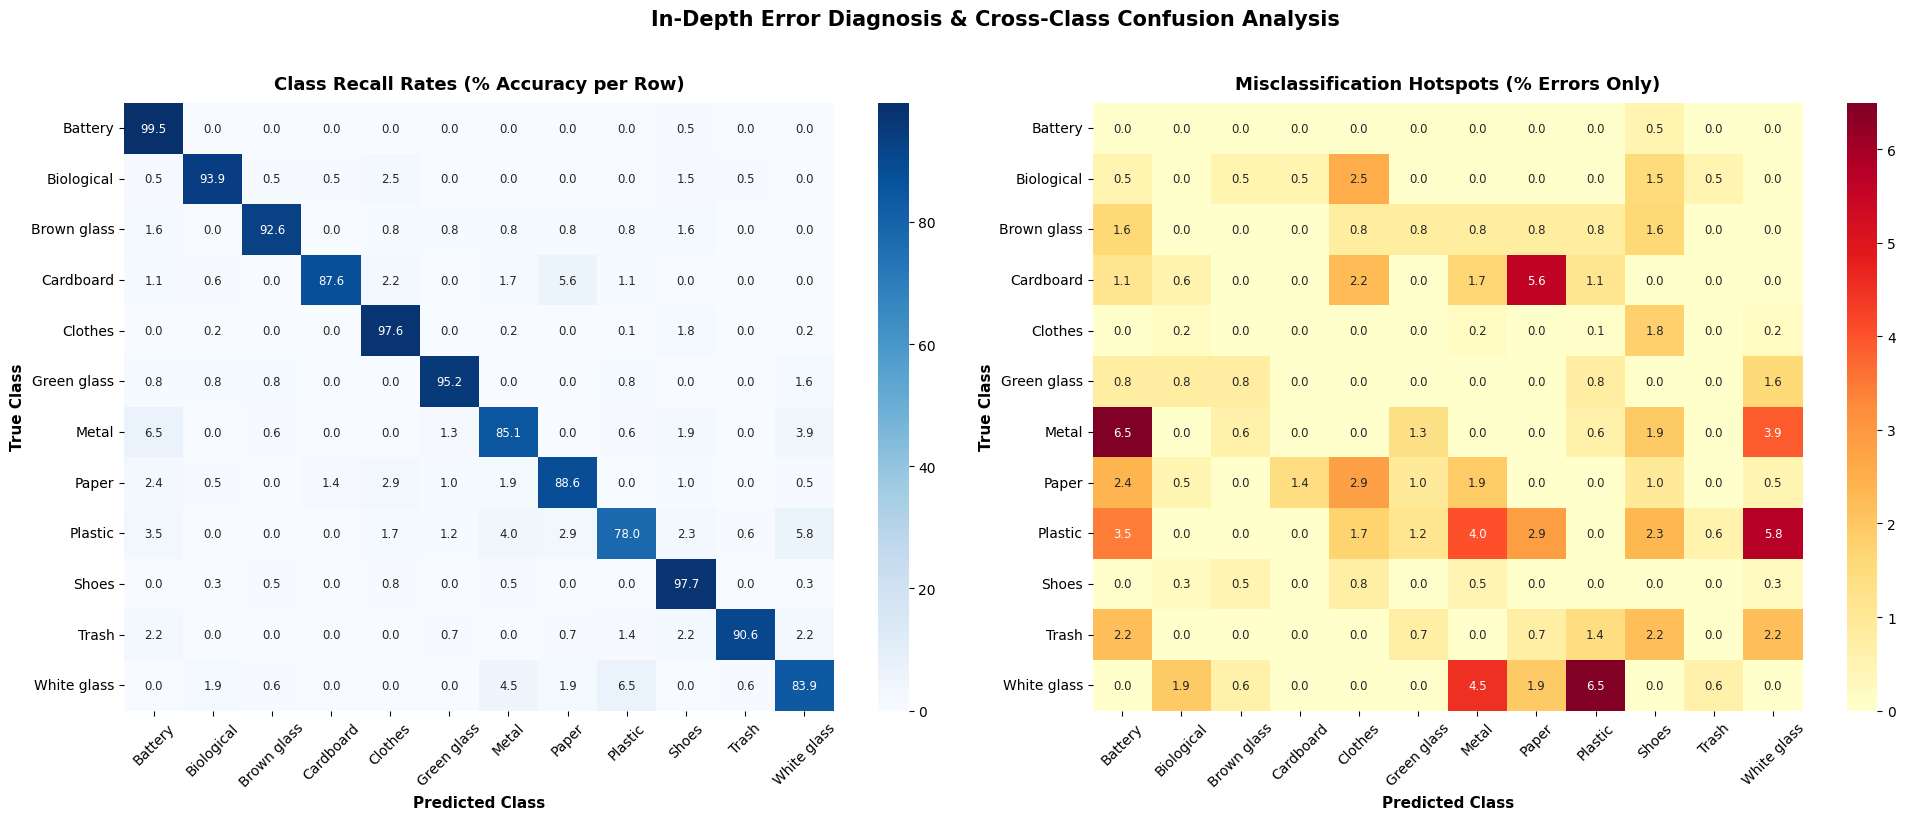

In [26]:
# ==============================================================================
# Chart 3: Normalized Recall Matrix & Error Hotspots Dual-Heatmap
# ==============================================================================
# Normalized confusion matrix (percentage of true class recalled)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

# Error-only matrix: zero out the correct predictions (diagonal)
cm_errors_only = cm_normalized.copy()
np.fill_diagonal(cm_errors_only, 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Left: Full Normalized Recall Matrix
sns.heatmap(
    cm_normalized, annot=True, fmt=".1f", cmap="Blues",
    xticklabels=formatted_classes, yticklabels=formatted_classes,
    cbar=True, ax=ax1, annot_kws={"size": 8.5}
)
ax1.set_title("Class Recall Rates (% Accuracy per Row)", fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel("Predicted Class", fontsize=11, fontweight='bold')
ax1.set_ylabel("True Class", fontsize=11, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

# Right: Off-Diagonal Error Hotspots (Where Confusion Happens)
sns.heatmap(
    cm_errors_only, annot=True, fmt=".1f", cmap="YlOrRd",
    xticklabels=formatted_classes, yticklabels=formatted_classes,
    cbar=True, ax=ax2, annot_kws={"size": 8.5}
)
ax2.set_title("Misclassification Hotspots (% Errors Only)", fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel("Predicted Class", fontsize=11, fontweight='bold')
ax2.set_ylabel("True Class", fontsize=11, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)

plt.suptitle("In-Depth Error Diagnosis & Cross-Class Confusion Analysis", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

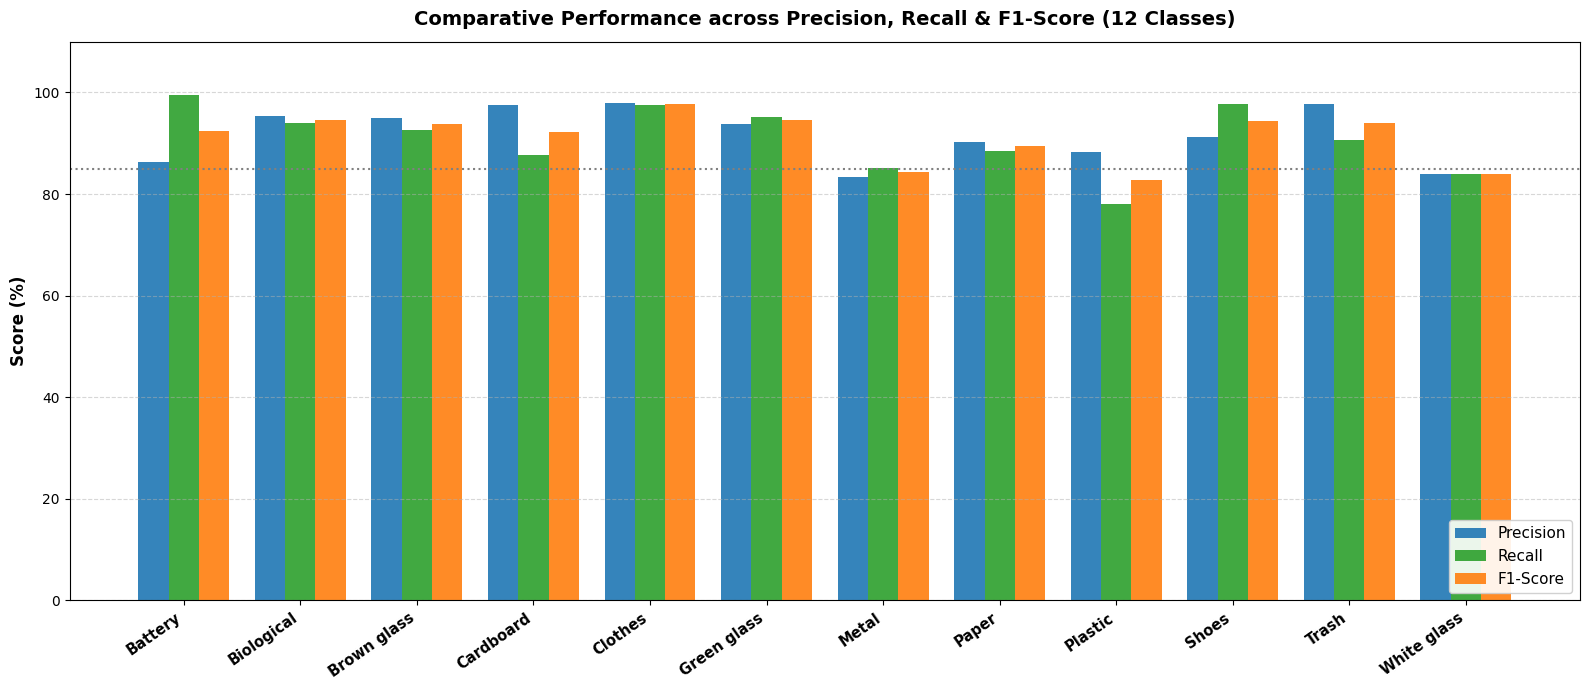

In [27]:
# ==============================================================================
# Chart 4: Triple Metric Grouped Bar Chart (Precision vs. Recall vs. F1)
# ==============================================================================
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    all_targets, all_predictions, average=None
)

x = np.arange(len(formatted_classes))
width = 0.26

plt.figure(figsize=(16, 7))

# Clustered Bars
rects1 = plt.bar(x - width, precision * 100, width, label='Precision', color='#1f77b4', alpha=0.9)
rects2 = plt.bar(x, recall * 100, width, label='Recall', color='#2ca02c', alpha=0.9)
rects3 = plt.bar(x + width, f1 * 100, width, label='F1-Score', color='#ff7f0e', alpha=0.9)

plt.ylabel("Score (%)", fontsize=12, fontweight='bold')
plt.title("Comparative Performance across Precision, Recall & F1-Score (12 Classes)", fontsize=14, fontweight='bold', pad=12)
plt.xticks(x, formatted_classes, rotation=35, ha='right', fontsize=10.5, fontweight='bold')
plt.ylim(0, 110)
plt.legend(loc='lower right', fontsize=11, framealpha=0.9)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Benchmark 85% goal line
plt.axhline(y=85, color='gray', linestyle=':', linewidth=1.5, label='85% Target Line')

plt.tight_layout()
plt.show()

## 9. Google Colab Tesla T4 Execution Summary

| Configuration Parameter | Value | Rationale |
| :--- | :--- | :--- |
| **Hardware** | Google Colab Tesla T4 (15GB VRAM) | Enables fast mixed-precision training |
| **Model Backbone** | `torchvision.models.efficientnet_b0` | High accuracy-to-parameter ratio (~4M params) |
| **Target Classes** | 12 Garbage Categories | Replaced classifier head |
| **Input Resolution** | 224 x 224 | Standard ImageNet resolution |
| **Batch Size** | 32 | Balanced gradient stability & T4 memory bandwidth |
| **Num Workers** | 2 | Optimal for Google Colab's 2 vCPUs |
| **Pin Memory** | Enabled (`True`) | Fast DMA host-to-GPU transfer |
| **Precision** | PyTorch AMP (`float16`) | 2x speedup on Tensor Cores |
| **Optimizer** | `Adam(lr=0.001, weight_decay=1e-4)` | Fast convergence on frozen backbone head |
| **Scheduler** | `ReduceLROnPlateau(factor=0.5, patience=2)` | Dynamic fine-tuning of learning rate |
| **Checkpoint** | `best_garbage_classifier.pth` | Automatically keeps the highest accuracy epoch |
